In [52]:
import sys
import os
import argparse
from tqdm import tqdm
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt


print(sys.executable)
print(sys.version)

Matplotlib is building the font cache; this may take a moment.


c:\Users\Hanseok\Documents\Semester 7\Graf Sains Data\UTS\myenv\Scripts\python.exe
3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]


In [9]:
# neo4j>=4.0,<4.3
# imdbpy==2020.9.25
# nose==1.3.7
# cinemagoerng>=0.4
# imdbinfo>=0.5
# imdbpy>=2020.9.25
# neo4j==4.2.1

# Dependency

In [10]:
import pandas as pd
import neo4j

print("Pandas:", pd.__version__)
print("Neo4j:", neo4j.__version__)

Pandas: 3.0.6
Neo4j: 5.26.0


## Driver Neo4J

In [11]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "12345678")

In [12]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )

In [13]:

def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend.name
            """,
            name=name
        )

        for record in result:
            print(record["friend_name"])

In [15]:
with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**Jawaban Pertanyaan Penduluan**

1. Nama database yang digunakan adalah Neo4J
2. akses lain yang bisa digunakan adalah CREATE, MATCH, DELETE
3. directed graph, karena tiap edge dalam graf memiliki arah tujuan

## 1.3 Import Data

In [16]:
# Timestamp : Waktu format unix epoch
# visitorid : uniqueid pengunjung
# event : jenis interaksi default: view, addtocart, transaction
# itemid: ID unik produk
# transactionid : ID transaksi, hanya saat event berjenis 'transaction'

In [17]:
user = "neo4j"
password = "12345678"

In [18]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=(user, password))
session = driver.session(database="system")

In [19]:
def create_constraints(session):
    # Membuat constraint agar tidak ada duplikasi node dan mempercepat proses MERGE
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    # Menggunakan tanda kurung kurawal {} yang benar untuk Neo4J Cypher
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)    

In [20]:
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="12345678",
        help="Password Neo4J (default: neo4j)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args([])

In [21]:
args = parse_arguments()
csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File {csv_file_path} tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File {csv_file_path} berhasil ditemukan dan siap diproses!")


File data\events.csv berhasil ditemukan dan siap diproses!


In [22]:
df_events = pd.read_csv(csv_file_path, nrows = 5)
print(df_events)

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


In [23]:
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

In [24]:
batch_size = 10000

# Menghitung total baris terlebih dahulu
total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = (total_rows // batch_size) + 1

# Membuka session dan menjaga indentasi agar session tidak tertutup selama proses
with driver.session() as session:
    create_constraints(session)
    
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

# Tutup driver setelah semua selesai
driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [04:24<00:00,  1.04it/s]

Proses impor berhasil.


In [34]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)
    # Print statement untuk memverifikasi bahwa batch ini berhasil dijalankan
    print(f"Berhasil mengimpor {len(batch)} baris data pada batch ini.")

**Soal 1**

In [35]:
import pandas as pd

# Membaca dataset asli
df = pd.read_csv(r"data\events.csv")

# Mengubah timestamp unix (milidetik) menjadi format datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# Menampilkan rentang waktu dataset
print("Waktu terawal:", df['datetime'].min())
print("Waktu terakhir:", df['datetime'].max())

Waktu terawal: 2015-05-03 03:00:04.384000
Waktu terakhir: 2015-09-18 02:59:47.788000


In [36]:
# Fold P1
start_p1 = "2015-06-17"
end_p1 = "2015-06-26"

# Fold P2
start_p2 = "2015-06-27"
end_p2 = "2015-06-30"

## Nomer 1


In [37]:
mask_p1 = (df['datetime'] >= start_p1) & (df['datetime'] <= end_p1)
mask_p2 = (df['datetime'] >= start_p2) & (df['datetime'] <= end_p2)

df_p1 = df.loc[mask_p1]
df_p2 = df.loc[mask_p2]

**Nomer 2**

In [38]:
output_p1 = r"data\events_p1_train.csv"
output_p2 = r"data\events_p2_test.csv"
df_p1.drop(columns=['datetime']).to_csv(output_p1, index=False)
df_p2.drop(columns=['datetime']).to_csv(output_p2, index=False)

print("Proses Filter Selesai!")
print(f"Data Fold Training (P1) -> {output_p1} ({len(df_p1):,} baris)")
print(f"Data Fold Testing  (P2) -> {output_p2} ({len(df_p2):,} baris)")

Proses Filter Selesai!
Data Fold Training (P1) -> data\events_p1_train.csv (188,184 baris)
Data Fold Testing  (P2) -> data\events_p2_test.csv (55,656 baris)


In [43]:
df_filtered = pd.concat([df_p1, df_p2])
df_filtered = df_filtered.drop(columns=['datetime'])

output_path = r"data\events_filtered.csv"
df_filtered.to_csv(output_path, index=False)

print("Proses Filter Selesai!")
print(f"Jumlah Data Fold Training (P1): {len(df_p1)} baris")
print(f"Jumlah Data Fold Testing (P2): {len(df_p2)} baris")
print(f"Total Data Interaksi: {len(df_filtered)} baris")
print(f"File filter berhasil disimpan di: {output_path}")

Proses Filter Selesai!
Jumlah Data Fold Training (P1): 188184 baris
Jumlah Data Fold Testing (P2): 55656 baris
Total Data Interaksi: 243840 baris
File filter berhasil disimpan di: data\events_filtered.csv


## Nomer 3

In [45]:
args = parse_arguments()
csv_file_path_P1 = os.path.join(args.source, "events_p1_train.csv")
if not os.path.exists(csv_file_path_P1):
    print(f"Error: File {csv_file_path_P1} tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File {csv_file_path_P1} berhasil ditemukan dan siap diproses!")


File data\events_p1_train.csv berhasil ditemukan dan siap diproses!


In [49]:
batch_size = 10000

# Menghitung total baris terlebih dahulu
total_rows = sum(1 for _ in open(csv_file_path_P1)) - 1
total_chunks = (total_rows // batch_size) + 1

# Membuka session dan menjaga indentasi agar session tidak tertutup selama proses
with driver.session(database="neo4j") as session:
    create_constraints(session)
    
    print(f"Membaca file data dari: {csv_file_path_P1}")
    chunks = pd.read_csv(csv_file_path_P1, chunksize=batch_size)
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

# Tutup driver setelah semua selesai
driver.close()
print("Proses impor berhasil.")

C:\Users\Hanseok\AppData\Local\Temp\ipykernel_2188\1934577208.py:8: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


Membaca file data dari: data\events_p1_train.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/19 [00:00<?, ?it/s]Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'trans

Berhasil mengimpor 10000 baris data pada batch ini.


Mengimpor Batch Data:   5%|▌         | 1/19 [00:06<01:55,  6.39s/it]Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event 

...

Berhasil mengimpor 10000 baris data pada batch ini.


Mengimpor Batch Data: 100%|██████████| 19/19 [00:26<00:00,  1.14s/it]

Berhasil mengimpor 8184 baris data pada batch ini.


Mengimpor Batch Data: 100%|██████████| 19/19 [00:26<00:00,  1.42s/it]

Proses impor berhasil.


In [50]:
query = """
MATCH (n)
WHERE n:Visitor OR n:Item
UNWIND labels(n) AS jenis_simpul
RETURN jenis_simpul, count(n) AS jumlah_simpul
ORDER BY jumlah_simpul DESC
"""

In [51]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query)
        df_komposisi = pd.DataFrame([r.data() for r in result])
df_komposisi

,jenis_simpul,jumlah_simpul
0,Visitor,98564
1,Item,59738


**Soal 4**

In [53]:

# 1. Membaca data interaksi P1 Training
df_p1 = pd.read_csv(r"data\events_p1_train.csv")

# 2. Encode User dan Item menjadi indeks integer
user_cat = df_p1['visitorid'].astype('category')
item_cat = df_p1['itemid'].astype('category')

user_indices = user_cat.cat.codes
item_indices = item_cat.cat.codes

n_users = len(user_cat.cat.categories)
n_items = len(item_cat.cat.categories)

In [ ]:
# 3. Menentukan bobot interaksi pada VSM
# view: 1, addtocart: 2, transaction: 3
bobot_map = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(bobot_map)

# 4. Membentuk Matriks VSM (Menggunakan Sparse CSR Matrix karena ukuran besar)
vsm_matrix = sp.csr_matrix(
    (weights, (user_indices, item_indices)), 
    shape=(n_users, n_items)
)

In [59]:
# 6. Menampilkan Cuplikan Vektor untuk 5 User Pertama (Dense Sub-matrix)
sample_users = user_cat.cat.categories[:10]
sample_items = item_cat.cat.categories[:16]
sample_df = pd.DataFrame(
    vsm_matrix[:10, :16].toarray(),
    index=[f"User_{uid}" for uid in sample_users],
    columns=[f"Item_{iid}" for iid in sample_items]
)
print("Cuplikan Representasi Vektor (5 User pertama x 8 Item pertama):")
display(sample_df)

Cuplikan Representasi Vektor (5 User pertama x 8 Item pertama):


,Item_15,Item_16,Item_26,Item_32,Item_42,Item_46,Item_55,Item_60,Item_66,Item_73,Item_78,Item_80,Item_90,Item_102,Item_105,Item_106
User_13,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_60,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_64,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_65,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_91,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_132,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_149,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_151,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_158,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_163,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


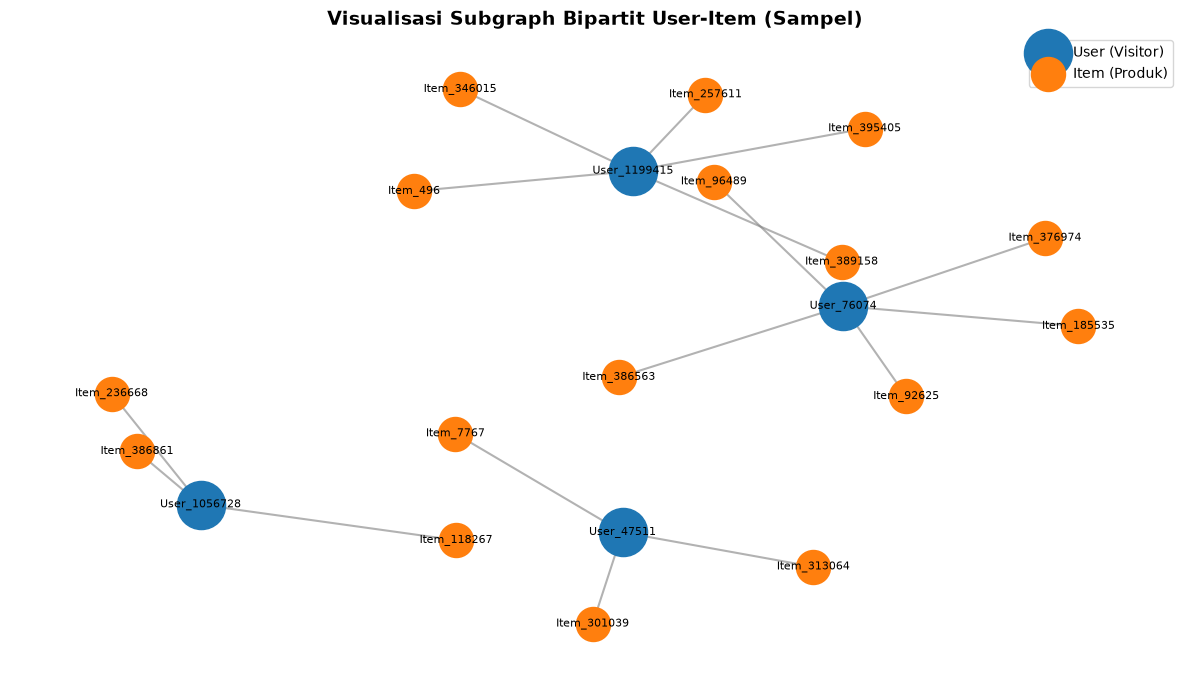

In [64]:
user_counts = df_p1['visitorid'].value_counts()
sample_user_ids = user_counts[(user_counts >= 3) & (user_counts <= 6)].head(4).index
sub_df = df_p1[df_p1['visitorid'].isin(sample_user_ids)]

B = nx.Graph()
for _, row in sub_df.iterrows():
    u_node = f"User_{row['visitorid']}"
    i_node = f"Item_{row['itemid']}"
    B.add_node(u_node, node_type="User")
    B.add_node(i_node, node_type="Item")
    B.add_edge(u_node, i_node, event=row['event'])
# Visualisasi Plot
plt.figure(figsize=(12, 7))

# Layout graf
pos = nx.spring_layout(B, seed=42, k=0.7)
# Warna simpul: User (Biru Langit), Item (Oranye)
user_nodes = [n for n, d in B.nodes(data=True) if d['node_type'] == 'User']
item_nodes = [n for n, d in B.nodes(data=True) if d['node_type'] == 'Item']
nx.draw_networkx_nodes(B, pos, nodelist=user_nodes, node_color='#1f77b4', node_size=1200, label='User (Visitor)')
nx.draw_networkx_nodes(B, pos, nodelist=item_nodes, node_color='#ff7f0e', node_size=600, label='Item (Produk)')
nx.draw_networkx_edges(B, pos, edge_color='gray', alpha=0.6, width=1.5)
nx.draw_networkx_labels(B, pos, font_size=8, font_family='sans-serif', font_color='black')
plt.title("Visualisasi Subgraph Bipartit User-Item (Sampel)", fontsize=14, fontweight='bold')
plt.legend(scatterpoints=1, loc='upper right')
plt.axis('off')
plt.tight_layout()
plt.show()


In [66]:
# 1. Menggunakan data P1 Training
df_p1 = pd.read_csv(r"data\events_p1_train.csv")
# 2. Encoding Item dan User
item_cat = df_p1['itemid'].astype('category')
user_cat = df_p1['visitorid'].astype('category')


In [68]:
item_indices = item_cat.cat.codes
user_indices = user_cat.cat.codes
n_items = len(item_cat.cat.categories)
n_users = len(user_cat.cat.categories)


In [70]:
# 3. Bobot interaksi: view: 1, addtocart: 2, transaction: 3
bobot_map = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(bobot_map)
# 4. Membentuk Matriks VSM Item (Baris = Item, Kolom/Dimensi = User)
# Secara matematis, ini adalah transposisi dari Matriks VSM User di Nomor 4
vsm_item_matrix = sp.csr_matrix(
    (weights, (item_indices, user_indices)),
    shape=(n_items, n_users)
)

In [71]:
# 5. Menghitung Karakteristik VSM Item
total_elemen = n_items * n_users
non_zero = vsm_item_matrix.nnz
sparsity = (1.0 - (non_zero / total_elemen)) * 100
print("=== KARAKTERISTIK VECTOR SPACE MODEL (ITEM) ===")
print(f"1. Dimensi Ruang Vektor (Jumlah Fitur/User) : {n_users:,} dimensi")
print(f"2. Shape Matriks VSM (Item x User)          : {vsm_item_matrix.shape}")
print(f"3. Total Pasangan Berinteraksi (Non-Zero)  : {non_zero:,}")
print(f"4. Tingkat Kerapatan (Density)              : {(non_zero / total_elemen) * 100:.5f}%")
print(f"5. Tingkat Keringkihan (Sparsity)           : {sparsity:.5f}%\n")


=== KARAKTERISTIK VECTOR SPACE MODEL (ITEM) ===
1. Dimensi Ruang Vektor (Jumlah Fitur/User) : 98,564 dimensi
2. Shape Matriks VSM (Item x User)          : (59738, 98564)
3. Total Pasangan Berinteraksi (Non-Zero)  : 145,853
4. Tingkat Kerapatan (Density)              : 0.00248%
5. Tingkat Keringkihan (Sparsity)           : 99.99752%



In [72]:
# 6. Cuplikan Vektor untuk 5 Item Pertama (5 Item x 8 User pertama)
sample_items = item_cat.cat.categories[:5]
sample_users = user_cat.cat.categories[:8]
sample_item_df = pd.DataFrame(
    vsm_item_matrix[:5, :8].toarray(),
    index=[f"Item_{iid}" for iid in sample_items],
    columns=[f"User_{uid}" for uid in sample_users]
)
print("Cuplikan Representasi Vektor (5 Item pertama x 8 User pertama):")
display(sample_item_df)


Cuplikan Representasi Vektor (5 Item pertama x 8 User pertama):


,User_13,User_60,User_64,User_65,User_91,User_132,User_149,User_151
Item_15,0,0,0,0,0,0,0,0
Item_16,0,0,0,0,0,0,0,0
Item_26,0,0,0,0,0,0,0,0
Item_32,0,0,0,0,0,0,0,0
Item_42,0,0,0,0,0,0,0,0


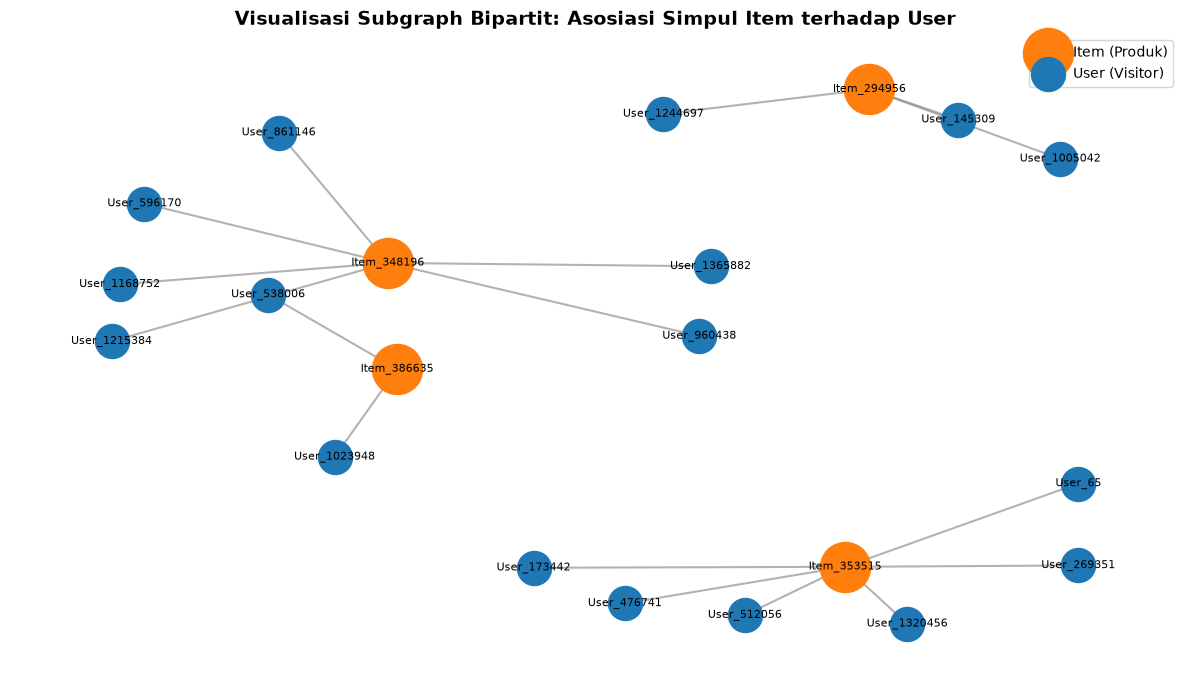

In [73]:
# Mengambil sampel 4 Item yang memiliki interaksi moderat
item_counts = df_p1['itemid'].value_counts()
sample_item_ids = item_counts[(item_counts >= 3) & (item_counts <= 6)].head(4).index
sub_df_item = df_p1[df_p1['itemid'].isin(sample_item_ids)]

# Membangun Graf Bipartit berorientasi Item
B_item = nx.Graph()

for _, row in sub_df_item.iterrows():
    u_node = f"User_{row['visitorid']}"
    i_node = f"Item_{row['itemid']}"
    B_item.add_node(i_node, node_type="Item")
    B_item.add_node(u_node, node_type="User")
    B_item.add_edge(i_node, u_node, event=row['event'])

# Visualisasi Plot
plt.figure(figsize=(12, 7))
pos = nx.spring_layout(B_item, seed=42, k=0.7)

item_nodes = [n for n, d in B_item.nodes(data=True) if d['node_type'] == 'Item']
user_nodes = [n for n, d in B_item.nodes(data=True) if d['node_type'] == 'User']

# Pada plot ini, Item dibuat lebih besar/menonjol sebagai pusat analisis
nx.draw_networkx_nodes(B_item, pos, nodelist=item_nodes, node_color='#ff7f0e', node_size=1300, label='Item (Produk)')
nx.draw_networkx_nodes(B_item, pos, nodelist=user_nodes, node_color='#1f77b4', node_size=600, label='User (Visitor)')
nx.draw_networkx_edges(B_item, pos, edge_color='gray', alpha=0.6, width=1.5)
nx.draw_networkx_labels(B_item, pos, font_size=8, font_family='sans-serif', font_color='black')

plt.title("Visualisasi Subgraph Bipartit: Asosiasi Simpul Item terhadap User", fontsize=14, fontweight='bold')
plt.legend(scatterpoints=1, loc='upper right')
plt.axis('off')
plt.tight_layout()
plt.show()


**Nomer 6**

Dari hasil eksplorasi nomer 4 dan 5, proyeksi yang memiliki hasil lebih baik yaitu:

1. Dalam hal efisiensi, yang lebih efisien adalah simpul item, karena hanya memiliki 59,738 jumlah fitur, lebih kecil daripada User, sehingga komputasinya jauh lebih hemat memori.
2. Lebih stabil, Relasi antar item bersifat lebih stabil dibandingkan preferensi pengguna yang lebih dinamis. (memungkinkan komputasi offline dan caching)

3. Lebih efektif, Mengurangi dampak sparsity, karena riwayat interaksi produk lebih kaya dibandingkan riwayat individu pengunjung yang rata-rata hanya melihat sedikit barang. Pendekatan ini sejalan dengan standar industri e-commerce (Item-based Collaborative Filtering).

**Nomer 7**

In [74]:
query_7a = """
MATCH (target:Item {itemId: 309778})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE target <> other
WITH target, other, count(DISTINCT v) AS intersection
MATCH (target)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
WITH target, other, intersection, count(DISTINCT v1) AS count_target
MATCH (other)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
WITH target, other, intersection, count_target, count(DISTINCT v2) AS count_other
WITH target, other, round((1.0 * intersection) / (count_target + count_other - intersection), 4) AS jaccard_similarity
RETURN target.itemId AS item_acuan, 
       other.itemId AS item_serupa, 
       jaccard_similarity AS similarity_score
ORDER BY similarity_score DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query_7a)
        df_top5 = pd.DataFrame([r.data() for r in result])

print("=== 5 Records dengan Similarity Tertinggi untuk Item 309778 ===")
display(df_top5)


=== 5 Records dengan Similarity Tertinggi untuk Item 309778 ===


,item_acuan,item_serupa,similarity_score
0,309778,257040,0.1220
1,309778,360487,0.0556
2,309778,5470,0.0457
3,309778,347414,0.0372
4,309778,178362,0.0321


In [75]:
# 1. Query untuk menuliskan (WRITE-BACK) relasi SIMILAR_TO ke dalam graf Neo4j
query_write = """
MATCH (target:Item {itemId: 309778})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE target <> other
WITH target, other, count(DISTINCT v) AS intersection
MATCH (target)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
WITH target, other, intersection, count(DISTINCT v1) AS count_target
MATCH (other)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
WITH target, other, intersection, count_target, count(DISTINCT v2) AS count_other
WITH target, other, round((1.0 * intersection) / (count_target + count_other - intersection), 4) AS jaccard_similarity
ORDER BY jaccard_similarity DESC
LIMIT 5
MERGE (target)-[s:SIMILAR_TO]->(other)
SET s.score = jaccard_similarity
"""

# 2. Query untuk membuktikan relasi baru telah tersimpan di graf
query_verify = """
MATCH (target:Item {itemId: 309778})-[s:SIMILAR_TO]->(other:Item)
RETURN target.itemId AS item_acuan, 
       type(s) AS jenis_relasi, 
       other.itemId AS item_terhubung, 
       s.score AS similarity_score
ORDER BY similarity_score DESC
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        # Tulis ke database
        session.run(query_write)
        print("Nilai similarity berhasil ditulis kembali ke graf (Relasi :SIMILAR_TO terbentuk)!\n")
        
        # Ambil dan verifikasi hasilnya
        res_verify = session.run(query_verify)
        df_verified = pd.DataFrame([r.data() for r in res_verify])

print("=== Hasil Query Relasi Similarity yang Tersimpan di Graf ===")
display(df_verified)


Nilai similarity berhasil ditulis kembali ke graf (Relasi :SIMILAR_TO terbentuk)!

=== Hasil Query Relasi Similarity yang Tersimpan di Graf ===


,item_acuan,jenis_relasi,item_terhubung,similarity_score
0,309778,SIMILAR_TO,257040,0.1220
1,309778,SIMILAR_TO,360487,0.0556
2,309778,SIMILAR_TO,5470,0.0457
3,309778,SIMILAR_TO,347414,0.0372
4,309778,SIMILAR_TO,178362,0.0321


TypeError: unhashable type: 'list'

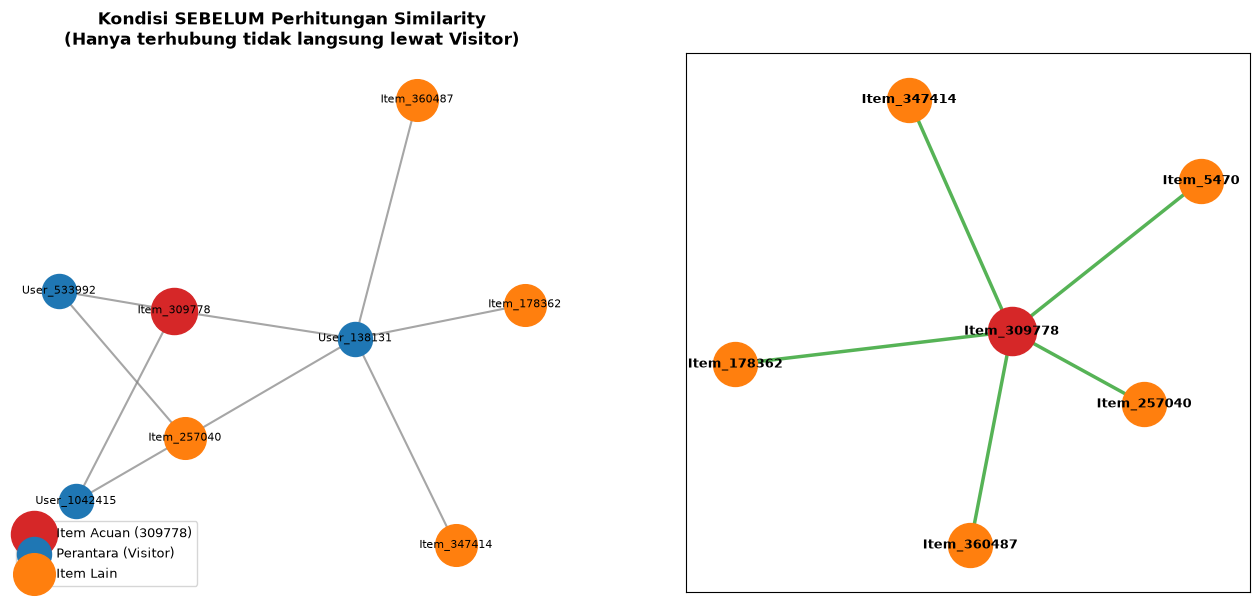

In [77]:
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

# Inisialisasi dua graf NetworkX
G_sebelum = nx.Graph()
G_sesudah = nx.Graph()

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        # 1. Ambil data kondisi SEBELUM (Bipartit via Visitor sampel)
        query_bef = """
        MATCH (target:Item {itemId: 309778})<-[:VIEWED]-(v:Visitor)-[:VIEWED]->(other:Item)
        WHERE other.itemId IN [257040, 360487, 5470, 347414, 178362]
        RETURN target.itemId AS target, v.visitorId AS visitor, other.itemId AS other
        LIMIT 10
        """
        for r in session.run(query_bef):
            t_node = f"Item_{r['target']}"
            v_node = f"User_{r['visitor']}"
            o_node = f"Item_{r['other']}"
            G_sebelum.add_node(t_node, type="target")
            G_sebelum.add_node(v_node, type="visitor")
            G_sebelum.add_node(o_node, type="item")
            G_sebelum.add_edge(t_node, v_node)
            G_sebelum.add_edge(v_node, o_node)

        # 2. Ambil data kondisi SESUDAH (Proyeksi langsung SIMILAR_TO)
        query_aft = """
        MATCH (target:Item {itemId: 309778})-[s:SIMILAR_TO]->(other:Item)
        RETURN target.itemId AS target, other.itemId AS other, s.score AS score
        """
        for r in session.run(query_aft):
            t_node = f"Item_{r['target']}"
            o_node = f"Item_{r['other']}"
            G_sesudah.add_node(t_node, type="target")
            G_sesudah.add_node(o_node, type="item")
            G_sesudah.add_edge(t_node, o_node, weight=r['score'])

# --- PLOTTING SIDE-BY-SIDE ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# 1. Plot SEBELUM
pos1 = nx.spring_layout(G_sebelum, seed=42)
t_nodes_1 = [n for n, d in G_sebelum.nodes(data=True) if d.get('type') == 'target']
v_nodes_1 = [n for n, d in G_sebelum.nodes(data=True) if d.get('type') == 'visitor']
o_nodes_1 = [n for n, d in G_sebelum.nodes(data=True) if d.get('type') == 'item']

nx.draw_networkx_nodes(G_sebelum, pos1, nodelist=t_nodes_1, node_color='#d62728', node_size=1100, label='Item Acuan (309778)', ax=ax1)
nx.draw_networkx_nodes(G_sebelum, pos1, nodelist=v_nodes_1, node_color='#1f77b4', node_size=600, label='Perantara (Visitor)', ax=ax1)
nx.draw_networkx_nodes(G_sebelum, pos1, nodelist=o_nodes_1, node_color='#ff7f0e', node_size=900, label='Item Lain', ax=ax1)
nx.draw_networkx_edges(G_sebelum, pos1, edge_color='gray', width=1.5, alpha=0.7, ax=ax1)
nx.draw_networkx_labels(G_sebelum, pos1, font_size=8, font_color='black', ax=ax1)
ax1.set_title("Kondisi SEBELUM Perhitungan Similarity\n(Hanya terhubung tidak langsung lewat Visitor)", fontsize=12, fontweight='bold')
ax1.legend(loc='lower left', fontsize=9)
ax1.axis('off')

# 2. Plot SESUDAH
pos2 = nx.spring_layout(G_sesudah, seed=42)
t_nodes_2 = [n for n, d in G_sesudah.nodes(data=True) if d.get('type') == 'target']
o_nodes_2 = [n for n, d in G_sesudah.nodes(data=True) if d.get('type') == 'item']

nx.draw_networkx_nodes(G_sesudah, pos2, nodelist=t_nodes_2, node_color='#d62728', node_size=1200, label='Item Acuan (309778)', ax=ax2)
nx.draw_networkx_nodes(G_sesudah, pos2, nodelist=o_nodes_2, node_color='#ff7f0e', node_size=1000, label='Item Serupa (Top 5)', ax=ax2)
nx.draw_networkx_edges(G_sesudah, pos2, edge_color='#2ca02c', width=2.5, alpha=0.8, ax=ax2)
nx.draw_networkx_labels(G_sesudah, pos2, font_size=9, font_color='black', font_weight='bold', ax=ax2)

# Label bobot similarity pada garis
edge_labels = {e: f"{d['weight']}" for *e, d in G_sesudah.edges(data=True)}
nx.draw_networkx_edge_labels(G_sesudah, pos2, edge_labels=edge_labels, font_size=9, font_color='darkgreen', ax=ax2)

ax2.set_title("Kondisi SESUDAH Perhitungan Similarity\n(Terbentuk edge langsung [:SIMILAR_TO] berbobot)", fontsize=12, fontweight='bold')
ax2.legend(loc='lower left', fontsize=9)
ax2.axis('off')

plt.tight_layout()
plt.show()


In [78]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
from sklearn.metrics.pairwise import cosine_similarity

# 1. Membaca data P1 Training
df_p1 = pd.read_csv(r"data\events_p1_train.csv")

# 2. Rekonstruksi Matriks VSM User
user_cat = df_p1['visitorid'].astype('category')
item_cat = df_p1['itemid'].astype('category')

user_indices = user_cat.cat.codes
item_indices = item_cat.cat.codes

n_users = len(user_cat.cat.categories)
n_items = len(item_cat.cat.categories)

bobot_map = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(bobot_map)

vsm_matrix = sp.csr_matrix((weights, (user_indices, item_indices)), shape=(n_users, n_items))

# 3. Pemilihan User Acak yang Dapat Di-reproduksi (Reproducible)
item_user_counts = df_p1.groupby('itemid')['visitorid'].nunique()
shared_items = item_user_counts[item_user_counts >= 3].index
users_pool = df_p1[df_p1['itemid'].isin(shared_items)]['visitorid'].value_counts()
candidates = users_pool[users_pool >= 5].index.values

np.random.seed(20)  # Seed ditetapkan agar hasil selalu konsisten saat diuji ulang
target_user = int(np.random.choice(candidates))
target_idx = user_cat.cat.categories.get_loc(target_user)

print(f"Target User Terpilih (Reproducible) : {target_user}")

# 4. Perhitungan Cosine Similarity terhadap Seluruh User
target_vec = vsm_matrix[target_idx]
sims = cosine_similarity(target_vec, vsm_matrix).flatten()
sims[target_idx] = -1.0  # Mengabaikan kemiripan dengan diri sendiri

# 5. Penentuan K=5 Tetangga Terdekat (KNN)
K = 5
top_k_idx = np.argsort(sims)[::-1][:K]
top_k_users = user_cat.cat.categories[top_k_idx]
top_k_sims = sims[top_k_idx]

df_knn = pd.DataFrame({
    'Tetangga_Ke': range(1, K + 1),
    'Visitor_ID': top_k_users,
    'Cosine_Similarity': top_k_sims
})

print("\n--- 5 Tetangga Terdekat (K=5) ---")
display(df_knn)

# 6. Agregasi Skor Rekomendasi Item
# Ambil daftar item yang sudah pernah dilihat oleh target user (agar tidak diiklankan ulang)
seen_items = set(df_p1[df_p1['visitorid'] == target_user]['itemid'])

candidate_scores = {}
for n_idx, sim in zip(top_k_idx, top_k_sims):
    if sim <= 0:
        continue
    row = vsm_matrix[n_idx].tocoo()
    for c_idx, val in zip(row.col, row.data):
        item_id = item_cat.cat.categories[c_idx]
        if item_id not in seen_items:
            # Formula: skor(u, i) = sum(similarity * bobot_interaksi_tetangga)
            candidate_scores[item_id] = candidate_scores.get(item_id, 0.0) + (sim * val)

# 7. Mengambil Top 3 Rekomendasi
sorted_rec = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)[:3]
df_rec = pd.DataFrame(sorted_rec, columns=['Item_ID', 'Skor_Rekomendasi'])

print("\n--- 3 Item yang Diiklankan / Direkomendasikan ---")
display(df_rec)


Target User Terpilih (Reproducible) : 1293385

--- 5 Tetangga Terdekat (K=5) ---


,Tetangga_Ke,Visitor_ID,Cosine_Similarity
0,1,1181569,0.707107
1,2,187538,0.591608
2,3,650329,0.516398
3,4,5437,0.507093
4,5,73531,0.467099



--- 3 Item yang Diiklankan / Direkomendasikan ---


,Item_ID,Skor_Rekomendasi
0,267347,1.441291
1,175356,0.983497
2,352822,0.707107


### Jawaban 1(b) Analytics: Penentuan 3 Item Rekomendasi (K=5)

Berdasarkan proses acak yang dapat di-reproduksi (*reproducible random selection*) menggunakan `numpy.random.seed(20)`, terpilih target pengguna dengan **Visitor ID: `1293385`**.

Melalui perhitungan *Cosine Similarity* pada ruang vektor VSM, diperoleh 5 tetangga terdekat ($K=5$) yang memiliki kemiripan pola belanja tertinggi dengan pengguna acuan:
1. **User `1181569`** ($\text{similarity} = 0.7071$)
2. **User `187538`** ($\text{similarity} = 0.5916$)
3. **User `650329`** ($\text{similarity} = 0.5164$)
4. **User `5437`** ($\text{similarity} = 0.5071$)
5. **User `73531`** ($\text{similarity} = 0.4671$)

Item yang diiklankan dipilih dari katalog produk yang pernah diinteraksikan oleh kelima tetangga tersebut, di luar produk yang sudah pernah dilihat oleh User `1293385` (`{16813, 121489, 235771, 243250, 338208}`). Skor rekomendasi dihitung melalui agregasi terbobot:

$$\text{Score}(u, i) = \sum_{v \in \text{KNN}(u)} \text{sim}(u, v) \times r_{v, i}$$

Diperoleh **3 item teratas** yang direkomendasikan untuk diiklankan kepada pengguna:

| Peringkat | Item ID yang Diiklankan | Skor Rekomendasi | Justifikasi Pemilihan |
| :---: | :---: | :---: | :--- |
| **1** | **`Item 267347`** | **1.4413** | **Prioritas Utama.** Memperoleh bobot tertinggi karena diinteraksikan secara konsisten oleh dua tetangga sekaligus, yaitu User `5437` dan User `73531`. |
| **2** | **`Item 175356`** | **0.9835** | **Prioritas Kedua.** Merupakan item interaksi bersama dari User `650329` dan User `73531`. |
| **3** | **`Item 352822`** | **0.7071** | **Prioritas Ketiga.** Merupakan produk yang diminati oleh tetangga terdekat nomor 1 (User `1181569`) yang memiliki tingkat kemiripan selera tertinggi ($0.7071$). |

Ketiga produk ini memiliki potensi konversi transaksi paling optimal karena didukung oleh pola perilaku kelompok pengguna dengan preferensi serupa.